# AI Model Experiment & Evaluation
**Starter Notebook**

Notebook ini adalah kerangka awal untuk membandingkan dua pendekatan AI dalam menyelesaikan task sentiment analysis ulasan pelanggan:
1. Model klasik Machine Learning (Scikit-learn)
2. LLM API (Gemini)

Isi tiap section sesuai instruksi di Assignment Brief. Jangan ubah struktur section, tapi silakan tambah cell baru di dalam tiap section jika diperlukan.

> 🔧 **Catatan Penyesuaian Dataset**
>
> Notebook ini menggunakan dataset `customer_reviews_sentiment.csv` dengan kolom `review_text` dan `sentiment` (nilai: `positif`/`negatif`).
>
> Apabila dataset final berbeda dari yang digunakan saat ini, sesuaikan bagian berikut:
> - Nama file pada `pd.read_csv(...)` di Section 2
> - Nama kolom teks dan label pada Section 3 (saat ini: `review_text`, `sentiment`)
> - Label yang diminta pada prompt LLM di Section 5.2 (saat ini: `positif`/`negatif`)
> - Studi Kasus pada Assignment Brief, apabila domain data berbeda dari e-commerce

## 1. Problem Statement

### 1. Objective (Tujuan Use Case)
Tim produk *e-commerce* berencana membangun fitur otomatis untuk mengklasifikasikan sentimen ulasan pelanggan (*positif* / *negatif*) pada halaman produk. Sebelum menentukan arsitektur sistem yang akan digunakan di lingkungan produksi, diperlukan eksperimen awal untuk membandingkan performa, efisiensi, dan *trade-off* antara dua pendekatan:
- **Pendekatan 1 (Model Klasik Machine Learning):** Melatih model klasifikasi teks sendiri menggunakan pustaka *Scikit-learn* (misalnya menggunakan ekstraksi fitur TF-IDF).
- **Pendekatan 2 (Large Language Model / LLM API):** Memanfaatkan *Gemini AI API* melalui teknik *prompting* (*zero-shot* atau *few-shot*) tanpa proses pelatihan ulang (*training*).

Hasil eksperimen ini bertujuan memberikan rekomendasi *technical approach* berbasis data yang paling optimal untuk dikembangkan lebih lanjut oleh tim.

### 2. Definisi Target / Label Prediksi
Tugas pemodelan ini adalah klasifikasi biner (*binary classification*) untuk memprediksi kategori sentimen berdasarkan teks ulasan pelanggan (`review_text`), dengan rincian label sebagai berikut:
- **`positif`:** Ulasan yang mencerminkan kepuasan, pujian, atau pengalaman baik pelanggan terhadap produk atau layanan.
- **`negatif`:** Ulasan yang mencerminkan keluhan, kekecewaan, kritik, atau pengalaman buruk pelanggan.

### 3. Batasan dan Asumsi
- **Sumber Data:** Eksperimen wajib menggunakan dataset standar yang disediakan (`customer_reviews_sentiment.csv`) yang berisi 200 sampel ulasan pelanggan, tanpa penambahan data eksternal, serta menjaga keaslian file mentah di dalam folder `data/`.
- **Keadilan Evaluasi (*Fair Comparison*):** Kedua pendekatan (model klasik *Scikit-learn* dan *Gemini AI API*) wajib dievaluasi menggunakan potongan *test set* yang identik.
- **Ruang Lingkup Model:** Pelatihan model *Deep Learning* dari *scratch* tidak termasuk dalam cakupan tugas ini. Evaluasi tidak hanya berfokus pada skor metrik tertinggi (*Accuracy, Precision, Recall, F1-Score*), tetapi juga mempertimbangkan aspek kepraktisan seperti kecepatan *inference*, kemudahan implementasi, dan potensi biaya operasional API.

## 2. Import Library & Load Dataset

In [2]:
# 🔧 Sesuaikan nama file jika dataset final berbeda
import os, json, time, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, accuracy_score, f1_score)

from google import genai
from google.genai import types
from pydantic import BaseModel

df = pd.read_csv('../data/customer_reviews_sentiment.csv')
df.head()

,review_id,product_name,review_text,sentiment
0,1,Kemeja Flanel,Pelayanan lambat dan tidak responsif saat diko...,negatif
1,2,Case HP,"Puas banget belanja disini, proses cepat dan b...",positif
2,3,Rice Cooker,"Terima kasih seller, barangnya awet dan sesuai...",positif
3,4,Case HP,Warna produk berbeda jauh dari foto di listing.,negatif
4,5,Headset Bluetooth,"Terima kasih seller, barangnya awet dan sesuai...",positif


## 3. Menyiapkan Train/Test Split

Pastikan test set yang sama digunakan untuk kedua pendekatan agar perbandingan adil.

Note: Karena ada anomali pada data, dibutuhkan preprocessing terlebih dahulu untuk mengatasa duplikasi data sebelum melakukan persiapan train/test split, sehingga proses pada section ini dilakukan pada section 4.

## 4. Pendekatan 1 — Model Klasik (Scikit-learn)

### 4.1 Preprocessing & Feature Extraction

In [6]:
# ============================================================
# 01_preprocessing_v2.py
# Tahap: validasi data -> cleaning -> dedup -> encode label -> stratified 5-fold
#
# VERSI IN-MEMORY: tidak menyimpan file apa pun ke folder data.
# Hasil akhir berupa variabel `df_clean` yang dipakai tahap berikutnya.
#
# Prasyarat: cell import (re, np, pd, StratifiedKFold) sudah dijalankan.
# Setiap blok "# %%" = satu cell notebook.
# ============================================================

# %% [1] Konfigurasi
RAW_PATH = "../data/customer_reviews_sentiment.csv"   # satu-satunya file yang dibaca

N_SPLITS = 5
SEED = 42
LABEL_MAP = {"negatif": 0, "positif": 1}

np.random.seed(SEED)


# %% [2] Load data mentah & cek struktur
# Dibaca ulang dari file asli agar cell ini aman dijalankan berulang kali.
df_raw = pd.read_csv(RAW_PATH, encoding="utf-8")

print("Shape            :", df_raw.shape)
print("\nTipe data:")
print(df_raw.dtypes)
print("\nMissing value per kolom:")
print(df_raw.isna().sum())
print("\nreview_id unik   :", df_raw["review_id"].is_unique)


# %% [3] Validasi baris & label
df = df_raw.copy()

# Buang baris yang teks/label-nya kosong
df = df.dropna(subset=["review_text", "sentiment"]).copy()

# Normalisasi penulisan: spasi di tepi, label huruf kecil
df["review_text"] = df["review_text"].astype(str).str.strip()
df["sentiment"] = df["sentiment"].astype(str).str.strip().str.lower()

# Buang teks yang kosong setelah di-strip
df = df[df["review_text"] != ""].copy()

unknown_labels = set(df["sentiment"].unique()) - set(LABEL_MAP)
assert not unknown_labels, f"Label tak dikenal ditemukan: {unknown_labels}"

print("Baris setelah validasi:", len(df))
print("\nDistribusi label (data mentah):")
print(df["sentiment"].value_counts())
print(df["sentiment"].value_counts(normalize=True).round(3))


# %% [4] Cleaning teks
# Hanya lowercase, hapus tanda baca/simbol, rapikan spasi.
# Stopword TIDAK dibuang dan TIDAK ada stemming: kata negasi/penguat
# ("tidak", "sangat", "belum") membawa sinyal penting, misalnya
# "tidak mengecewakan" (positif) vs "sangat mengecewakan" (negatif).
def clean_text(text: str) -> str:
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)  # hapus tanda baca, emoji, simbol
    text = re.sub(r"\s+", " ", text).strip()  # rapikan spasi
    return text


df["text_clean"] = df["review_text"].apply(clean_text)

assert (df["text_clean"] != "").all(), "Ada teks yang kosong setelah cleaning"

df[["review_text", "text_clean"]].head(5)


# %% [5] Analisis duplikasi
n_total = len(df)
n_unique = df["text_clean"].nunique()
freq = df["text_clean"].value_counts()

print(f"Total baris          : {n_total}")
print(f"Teks unik            : {n_unique}")
print(f"Baris duplikat       : {n_total - n_unique}")
print(f"Rata-rata kemunculan : {n_total / n_unique:.2f}x per teks")
print("\nRingkasan frekuensi kemunculan per teks:")
print(freq.describe().round(2))
print("\n10 teks paling sering muncul:")
print(freq.head(10))

# Cek konflik label: teks identik tetapi label berbeda
labels_per_text = df.groupby("text_clean")["sentiment"].nunique()
conflict_texts = labels_per_text[labels_per_text > 1].index
print(f"\nTeks dengan label konflik: {len(conflict_texts)}")
if len(conflict_texts) > 0:
    display(
        df[df["text_clean"].isin(conflict_texts)]
        .sort_values("text_clean")[["review_id", "review_text", "sentiment"]]
    )


# %% [6] Deduplikasi
# Satu baris per teks unik. Konflik label diselesaikan dengan suara mayoritas;
# jika seri, teks dibuang agar tidak menjadi label yang ambigu.
def resolve_label(series: pd.Series):
    counts = series.value_counts()
    if len(counts) > 1 and counts.iloc[0] == counts.iloc[1]:
        return np.nan
    return counts.index[0]


df_unique = (
    df.groupby("text_clean", sort=False)
    .agg(
        review_text=("review_text", "first"),       # teks asli (untuk Gemini)
        sentiment=("sentiment", resolve_label),
        n_occurrence=("review_id", "count"),        # berapa kali muncul di data asli
        n_products=("product_name", "nunique"),     # muncul di berapa produk berbeda
    )
    .reset_index()
)

n_before = len(df_unique)
df_unique = df_unique.dropna(subset=["sentiment"]).reset_index(drop=True)
print(f"Teks unik sebelum buang label seri : {n_before}")
print(f"Teks unik setelah buang label seri : {len(df_unique)}")


# %% [7] Encode label & ID teks
df_unique["label"] = df_unique["sentiment"].map(LABEL_MAP).astype(int)
df_unique.insert(0, "text_id", np.arange(len(df_unique)))

class_counts = df_unique["label"].value_counts().sort_index()
print("Distribusi label setelah dedup:")
print(df_unique["sentiment"].value_counts())

# Syarat StratifiedKFold: tiap kelas minimal N_SPLITS data
assert class_counts.min() >= N_SPLITS, (
    f"Kelas terkecil hanya {class_counts.min()} data, kurang dari N_SPLITS={N_SPLITS}"
)


# %% [8] Stratified 5-fold
# Kolom 'fold' = indeks fold di mana teks tersebut menjadi data TEST.
# Disimpan di dalam df_clean agar Scikit-learn dan Gemini memakai
# pembagian yang sama.
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

df_unique["fold"] = -1
for fold_idx, (_, test_idx) in enumerate(
    skf.split(df_unique["text_clean"], df_unique["label"])
):
    df_unique.loc[test_idx, "fold"] = fold_idx

assert (df_unique["fold"] >= 0).all(), "Ada teks yang belum masuk fold manapun"

print("Jumlah data test per fold & kelas:")
pd.crosstab(df_unique["fold"], df_unique["sentiment"], margins=True)


# %% [9] Hasil akhir preprocessing -> variabel df_clean (TIDAK disimpan ke file)
cols = [
    "text_id", "review_text", "text_clean",
    "sentiment", "label", "fold",
    "n_occurrence", "n_products",
]
df_clean = df_unique[cols].copy()

print(f"df_clean siap dipakai tahap berikutnya: {len(df_clean)} baris, {len(cols)} kolom")
df_clean.head(10)

Shape            : (200, 4)

Tipe data:
review_id       int64
product_name      str
review_text       str
sentiment         str
dtype: object

Missing value per kolom:
review_id       0
product_name    0
review_text     0
sentiment       0
dtype: int64

review_id unik   : True
Baris setelah validasi: 200

Distribusi label (data mentah):
sentiment
positif    110
negatif     90
Name: count, dtype: int64
sentiment
positif    0.55
negatif    0.45
Name: proportion, dtype: float64
Total baris          : 200
Teks unik            : 40
Baris duplikat       : 160
Rata-rata kemunculan : 5.00x per teks

Ringkasan frekuensi kemunculan per teks:
count    40.00
mean      5.00
std       2.40
min       1.00
25%       3.00
50%       5.00
75%       6.25
max      12.00
Name: count, dtype: float64

10 teks paling sering muncul:
text_clean
bahan nyaman dipakai ukuran pas tidak mengecewakan                       12
produknya rapi dan bersih tidak ada cacat sama sekali                     9
pengiriman lambat 

,text_id,review_text,text_clean,sentiment,label,fold,n_occurrence,n_products
0,0,Pelayanan lambat dan tidak responsif saat diko...,pelayanan lambat dan tidak responsif saat diko...,negatif,0,0,5,5
1,1,"Puas banget belanja disini, proses cepat dan b...",puas banget belanja disini proses cepat dan ba...,positif,1,4,4,4
2,2,"Terima kasih seller, barangnya awet dan sesuai...",terima kasih seller barangnya awet dan sesuai ...,positif,1,4,4,4
3,3,Warna produk berbeda jauh dari foto di listing.,warna produk berbeda jauh dari foto di listing,negatif,0,4,5,5
4,4,"Packing rapi, produk sesuai deskripsi. Recomme...",packing rapi produk sesuai deskripsi recommend...,positif,1,3,7,5
5,5,Sudah bayar mahal tapi kualitas jauh dari eksp...,sudah bayar mahal tapi kualitas jauh dari eksp...,negatif,0,3,5,4
6,6,"Belanja disini selalu puas, kualitas terjaga.",belanja disini selalu puas kualitas terjaga,positif,1,1,3,3
7,7,"Bahan nyaman dipakai, ukuran pas, tidak mengec...",bahan nyaman dipakai ukuran pas tidak mengecew...,positif,1,1,12,9
8,8,"Barang cacat produksi, jahitan lepas di bebera...",barang cacat produksi jahitan lepas di beberap...,negatif,0,0,2,2
9,9,"Barang yang datang tidak sesuai dengan foto, k...",barang yang datang tidak sesuai dengan foto ke...,negatif,0,2,1,1


### 4.2 Training Model

Shape   : (40, 8)
N_SPLITS: 5

Missing value per kolom:
text_id         0
review_text     0
text_clean      0
sentiment       0
label           0
fold            0
n_occurrence    0
n_products      0
dtype: int64


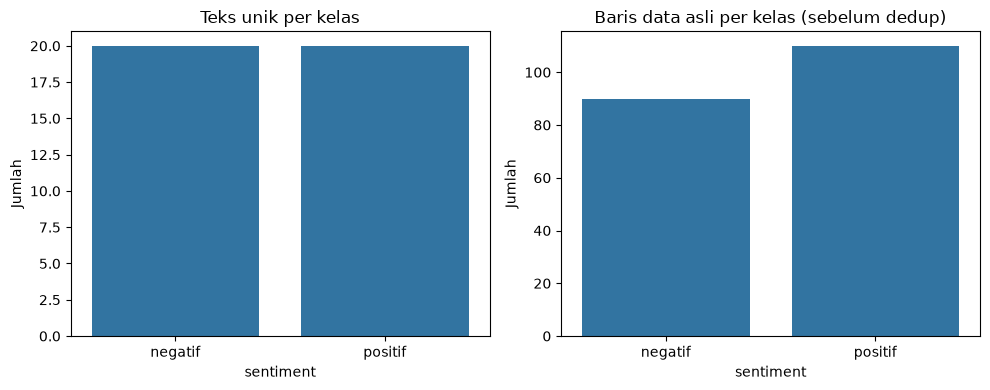

Teks unik per kelas : {'negatif': 20, 'positif': 20}
Baris asli per kelas: {'negatif': 90, 'positif': 110}


n_char                                          n_word            \
           count  mean  std   min   25%   50%   75%   max  count mean  std   
sentiment                                                                    
negatif     20.0  55.0  3.6  47.0  53.0  56.0  57.2  61.0   20.0  7.8  0.8   
positif     20.0  54.8  6.5  43.0  51.0  55.5  57.0  71.0   20.0  7.8  1.4   

                                     
           min  25%  50%  75%   max  
sentiment                            
negatif    6.0  7.0  8.0  8.0   9.0  
positif    6.0  6.8  8.0  9.0  11.0

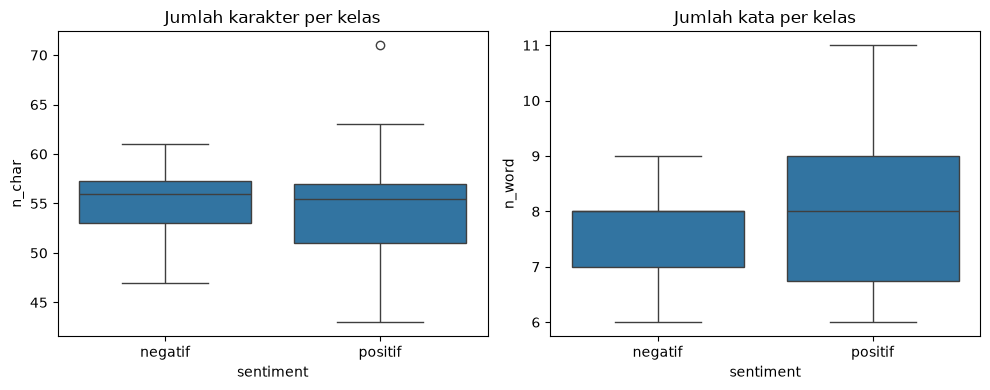


===== Kelas: negatif =====
Unigram teratas:


,ngram,count
0,tidak,9
1,barang,6
2,yang,5
3,dari,5
4,produk,5
5,sesuai,4
6,sekali,4
7,dan,4
8,lambat,3
9,sudah,3


Bigram teratas:


,ngram,count
0,tidak sesuai,4
1,jauh dari,3
2,sama sekali,2
3,sekali sudah,2
4,lambat dan,2
5,sesuai dengan,2
6,dalam kondisi,2
7,warna produk,1
8,ukuran dan,1
9,ukuran tidak,1



===== Kelas: positif =====
Unigram teratas:


,ngram,count
0,dan,7
1,cepat,7
2,kualitas,6
3,sesuai,5
4,puas,4
5,barang,4
6,dengan,4
7,produk,4
8,sangat,4
9,harga,3


... (6 outputs left out)

,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
negatif,20.0,4.5,2.14,1.0,2.75,5.0,6.0,8.0
positif,20.0,5.5,2.59,2.0,3.75,6.0,7.0,12.0



Teks yang muncul di lebih dari satu produk:
38 dari 40 teks unik


sentiment,negatif,positif
product_name,,
Blender Mini,0.50,0.50
Botol Minum,0.38,0.62
Case HP,0.59,0.41
Charger Cepat,0.43,0.57
Headset Bluetooth,0.50,0.50
Jaket Hoodie,0.31,0.69
Kaos Polos,0.67,0.33
Kemeja Flanel,0.50,0.50
Kursi Lipat,0.21,0.79


Kalau proporsi tiap produk relatif acak/mirip, product_name bukan sinyal yang kuat,
dan keputusan membuangnya dari fitur sudah tepat.


In [7]:
# ============================================================
# 02_eda_pipeline_sklearn_v2.py
# Tahap: EDA -> Pipeline Scikit-learn dengan stratified 5-fold
#
# VERSI IN-MEMORY: tidak menyimpan file apa pun ke folder data.
#
# Prasyarat:
#   - cell import (os, json, time, re, np, pd, plt, sns, Pipeline,
#     TfidfVectorizer, LogisticRegression, metrik sklearn) sudah dijalankan
#   - 01_preprocessing_v2.py sudah dijalankan (membuat variabel df_clean)
#
# Output untuk tahap berikutnya (variabel di memori):
#   df_clean  -> ditambah kolom pred_sklearn dan proba_pos_sklearn
#   sk_fold_metrics -> metrik & waktu per fold Scikit-learn
#
# Setiap blok "# %%" = satu cell notebook.
# ============================================================

# %% [1] Siapkan data (df_clean berasal dari 01_preprocessing_v2.py)
from sklearn.feature_extraction.text import CountVectorizer  # tambahan untuk EDA

RAW_PATH = "../data/customer_reviews_sentiment.csv"   # data awal, hanya dibaca
SEED = 42
LABEL_NAMES = {0: "negatif", 1: "positif"}

assert "df_clean" in globals(), (
    "df_clean belum ada. Jalankan 01_preprocessing_v2.py sampai blok 9 terlebih dulu."
)

N_SPLITS = df_clean["fold"].nunique()

print("Shape   :", df_clean.shape)
print("N_SPLITS:", N_SPLITS)
print("\nMissing value per kolom:")
print(df_clean.isna().sum())
assert df_clean["fold"].between(0, N_SPLITS - 1).all(), "Nilai fold tidak valid"
df_clean.head()


# ============================================================
# BAGIAN A: EDA
# ============================================================

# %% [2] Distribusi label: teks unik vs baris data asli
unique_counts = df_clean["sentiment"].value_counts()
raw_counts = df_clean.groupby("sentiment")["n_occurrence"].sum()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.barplot(x=unique_counts.index, y=unique_counts.values, ax=axes[0])
axes[0].set_title("Teks unik per kelas")
axes[0].set_ylabel("Jumlah")
sns.barplot(x=raw_counts.index, y=raw_counts.values, ax=axes[1])
axes[1].set_title("Baris data asli per kelas (sebelum dedup)")
axes[1].set_ylabel("Jumlah")
plt.tight_layout()
plt.show()

print("Teks unik per kelas :", unique_counts.to_dict())
print("Baris asli per kelas:", raw_counts.to_dict())


# %% [3] Panjang teks per kelas
df_clean["n_char"] = df_clean["review_text"].str.len()
df_clean["n_word"] = df_clean["text_clean"].str.split().str.len()

display(df_clean.groupby("sentiment")[["n_char", "n_word"]].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(data=df_clean, x="sentiment", y="n_char", ax=axes[0])
axes[0].set_title("Jumlah karakter per kelas")
sns.boxplot(data=df_clean, x="sentiment", y="n_word", ax=axes[1])
axes[1].set_title("Jumlah kata per kelas")
plt.tight_layout()
plt.show()


# %% [4] N-gram teratas per kelas (dihitung pada teks unik)
def top_ngrams(texts, ngram_range, n=10):
    cv = CountVectorizer(ngram_range=ngram_range)
    X_counts = cv.fit_transform(texts)
    counts = np.asarray(X_counts.sum(axis=0)).ravel()
    vocab = np.array(cv.get_feature_names_out())
    idx = counts.argsort()[::-1][:n]
    return pd.DataFrame({"ngram": vocab[idx], "count": counts[idx]})


for name in ["negatif", "positif"]:
    texts = df_clean.loc[df_clean["sentiment"] == name, "text_clean"]
    print(f"\n===== Kelas: {name} =====")
    print("Unigram teratas:")
    display(top_ngrams(texts, (1, 1)))
    print("Bigram teratas:")
    display(top_ngrams(texts, (2, 2)))


# %% [5] Kata yang muncul di KEDUA kelas (sumber ambiguitas bag-of-words)
cv_uni = CountVectorizer(ngram_range=(1, 1))
X_uni = cv_uni.fit_transform(df_clean["text_clean"])
vocab = np.array(cv_uni.get_feature_names_out())

is_pos = (df_clean["label"] == 1).to_numpy()
df_pos = np.asarray((X_uni[is_pos] > 0).sum(axis=0)).ravel()   # document frequency
df_neg = np.asarray((X_uni[~is_pos] > 0).sum(axis=0)).ravel()

overlap = pd.DataFrame({"word": vocab, "df_positif": df_pos, "df_negatif": df_neg})
shared = overlap[(overlap["df_positif"] > 0) & (overlap["df_negatif"] > 0)]

print(f"Ukuran kosakata       : {len(vocab)}")
print(f"Kata muncul di 2 kelas: {len(shared)} ({len(shared) / len(vocab):.1%} dari kosakata)")
print("\nKata bersama yang paling sering muncul:")
display(
    shared.assign(total=shared["df_positif"] + shared["df_negatif"])
    .sort_values("total", ascending=False)
    .head(15)
)

key_words = ["tidak", "sesuai", "cacat", "mengecewakan", "cepat", "lambat", "sangat"]
print("Kata kunci yang rawan ambigu:")
display(overlap[overlap["word"].isin(key_words)])


# %% [6] Frekuensi kemunculan asli per kelas
display(df_clean.groupby("sentiment")["n_occurrence"].describe().round(2))
print("\nTeks yang muncul di lebih dari satu produk:")
print((df_clean["n_products"] > 1).sum(), "dari", len(df_clean), "teks unik")


# %% [7] Cek product_name: apakah produk berkaitan dengan sentimen?
df_prod = pd.read_csv(RAW_PATH, encoding="utf-8")
df_prod["sentiment"] = df_prod["sentiment"].astype(str).str.strip().str.lower()

ct_prod = pd.crosstab(df_prod["product_name"], df_prod["sentiment"], normalize="index").round(2)
display(ct_prod)
print("Kalau proporsi tiap produk relatif acak/mirip, product_name bukan sinyal yang kuat,")
print("dan keputusan membuangnya dari fitur sudah tepat.")

### 4.3 Prediksi pada Test Set

,fold,n_train,n_test,accuracy,macro_f1,fit_sec,predict_ms_per_text
0,0,32,8,0.750,0.7500,0.0122,0.5190
1,1,32,8,0.750,0.7500,0.0104,0.4171
2,2,32,8,1.000,1.0000,0.0073,0.4813
3,3,32,8,0.750,0.7500,0.0068,0.3091
4,4,32,8,0.625,0.5636,0.0071,0.3818


Rata-rata ± std antar fold:
  Accuracy : 0.775 ± 0.137
  Macro-F1 : 0.763 ± 0.155
Accuracy gabungan : 0.775
Macro-F1 gabungan : 0.774

              precision    recall  f1-score   support

     negatif      0.824     0.700     0.757        20
     positif      0.739     0.850     0.791        20

    accuracy                          0.775        40
   macro avg      0.781     0.775     0.774        40
weighted avg      0.781     0.775     0.774        40



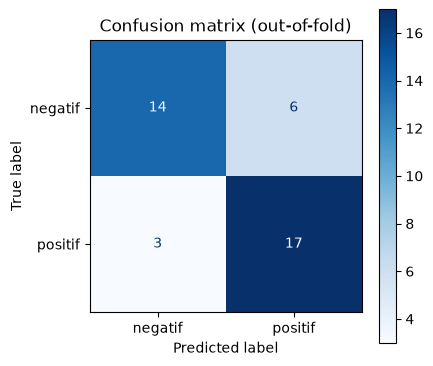

Jumlah teks salah prediksi: 9 dari 40


,text_id,review_text,sentiment,pred_sklearn,proba_pos_sklearn,fold
0,0,Pelayanan lambat dan tidak responsif saat diko...,negatif,1,0.518495,0
7,7,"Bahan nyaman dipakai, ukuran pas, tidak mengec...",positif,0,0.406430,1
10,10,Barang tidak berfungsi sama sekali begitu dite...,negatif,1,0.508108,1
18,18,"Bahan murahan, tidak sesuai dengan harga yang ...",negatif,1,0.506216,4
19,19,"Kualitas produk sangat memuaskan, akan order l...",positif,0,0.475944,0
20,20,"Sangat mengecewakan, uang saya seperti terbuan...",negatif,1,0.532741,4
21,21,"Ukuran dan warna berbeda dari pesanan, sangat ...",negatif,1,0.501860,3
24,24,"Produknya rapi dan bersih, tidak ada cacat sam...",positif,0,0.414212,3
30,30,"Pengalaman belanja terburuk, tidak akan order ...",negatif,1,0.576178,4


Fitur paling kuat mengarah ke NEGATIF:


,fitur,koef
0,tidak,-0.430
1,tidak sesuai,-0.335
2,yang,-0.303
3,jauh,-0.288
4,jauh dari,-0.288
5,lambat,-0.279
6,sekali,-0.249
7,dari,-0.228
8,lambat dan,-0.207
9,seperti,-0.205


Fitur paling kuat mengarah ke POSITIF:


,fitur,koef
0,cepat,0.508
1,puas,0.320
2,kualitas,0.301
3,banget,0.279
4,recommended,0.223
5,rapi,0.214
6,ada,0.206
7,selalu,0.203
8,seller,0.203
9,sesuai deskripsi,0.203


Koefisien bigram negasi (cek apakah model menangkap negasi):
  tidak mengecewakan    : +0.131
  sangat mengecewakan   : -0.118
  tidak ada             : +0.117
  tidak sesuai          : -0.335
  sesuai deskripsi      : +0.203
Tersimpan di memori: df_clean (dengan pred_sklearn) dan sk_fold_metrics


In [8]:
# ============================================================
# BAGIAN B: Pipeline Scikit-learn dengan stratified 5-fold
# ============================================================

# %% [8] Definisi pipeline
# Vectorizer ada DI DALAM pipeline, jadi di-fit hanya pada data train tiap fold
# (tidak ada kebocoran vocabulary/IDF dari data test).
# Hyperparameter sengaja dibuat tetap (tanpa tuning) agar skor bebas dari
# optimisme akibat tuning di fold yang sama.
def build_pipeline():
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)),
    ])


# %% [9] Jalankan 5-fold memakai kolom 'fold' dari preprocessing
# Fold yang sama nanti dipakai untuk Gemini agar perbandingannya adil.
X = df_clean["text_clean"]
y = df_clean["label"].to_numpy()

oof_pred = np.full(len(df_clean), -1, dtype=int)
oof_proba = np.full(len(df_clean), np.nan)
fold_rows = []

for k in range(N_SPLITS):
    train_idx = np.where(df_clean["fold"] != k)[0]
    test_idx = np.where(df_clean["fold"] == k)[0]

    pipe = build_pipeline()

    t0 = time.perf_counter()
    pipe.fit(X.iloc[train_idx], y[train_idx])
    t_fit = time.perf_counter() - t0

    t0 = time.perf_counter()
    pred = pipe.predict(X.iloc[test_idx])
    proba_pos = pipe.predict_proba(X.iloc[test_idx])[:, 1]
    t_pred = time.perf_counter() - t0

    oof_pred[test_idx] = pred
    oof_proba[test_idx] = proba_pos

    fold_rows.append({
        "fold": k,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "accuracy": accuracy_score(y[test_idx], pred),
        "macro_f1": f1_score(y[test_idx], pred, average="macro"),
        "fit_sec": t_fit,
        "predict_ms_per_text": t_pred / len(test_idx) * 1000,
    })

fold_df = pd.DataFrame(fold_rows)
assert (oof_pred >= 0).all(), "Ada teks yang belum punya prediksi out-of-fold"

display(fold_df.round(4))
print("Rata-rata ± std antar fold:")
print(f"  Accuracy : {fold_df['accuracy'].mean():.3f} ± {fold_df['accuracy'].std():.3f}")
print(f"  Macro-F1 : {fold_df['macro_f1'].mean():.3f} ± {fold_df['macro_f1'].std():.3f}")


# %% [10] Evaluasi gabungan (semua prediksi out-of-fold)
# Tiap teks unik diprediksi tepat satu kali oleh model yang tidak pernah melihatnya.
target_names = [LABEL_NAMES[0], LABEL_NAMES[1]]

print(f"Accuracy gabungan : {accuracy_score(y, oof_pred):.3f}")
print(f"Macro-F1 gabungan : {f1_score(y, oof_pred, average='macro'):.3f}\n")
print(classification_report(y, oof_pred, target_names=target_names, digits=3))

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(
    y, oof_pred, display_labels=target_names, cmap="Blues", ax=ax
)
ax.set_title("Confusion matrix (out-of-fold)")
plt.tight_layout()
plt.show()


# %% [11] Error analysis: teks yang salah diprediksi
df_clean["pred_sklearn"] = oof_pred
df_clean["proba_pos_sklearn"] = oof_proba

errors = df_clean[df_clean["pred_sklearn"] != df_clean["label"]]
print(f"Jumlah teks salah prediksi: {len(errors)} dari {len(df_clean)}")
if len(errors) > 0:
    display(errors[["text_id", "review_text", "sentiment", "pred_sklearn",
                    "proba_pos_sklearn", "fold"]])
else:
    print("Tidak ada kesalahan prediksi pada evaluasi 5-fold.")


# %% [12] Inspeksi fitur (HANYA untuk interpretasi, bukan untuk evaluasi)
# Model di-fit pada seluruh data agar koefisiennya stabil; skor tidak dihitung dari sini.
pipe_all = build_pipeline().fit(X, y)
features = pipe_all.named_steps["tfidf"].get_feature_names_out()
coef = pipe_all.named_steps["clf"].coef_[0]
order = np.argsort(coef)

print("Fitur paling kuat mengarah ke NEGATIF:")
display(pd.DataFrame({"fitur": features[order[:10]], "koef": coef[order[:10]].round(3)}))
print("Fitur paling kuat mengarah ke POSITIF:")
display(pd.DataFrame({"fitur": features[order[::-1][:10]], "koef": coef[order[::-1][:10]].round(3)}))

feat_idx = {f: i for i, f in enumerate(features)}
check = ["tidak mengecewakan", "sangat mengecewakan", "tidak ada", "tidak sesuai", "sesuai deskripsi"]
print("Koefisien bigram negasi (cek apakah model menangkap negasi):")
for f in check:
    if f in feat_idx:
        print(f"  {f:<22}: {coef[feat_idx[f]]:+.3f}")
    else:
        print(f"  {f:<22}: tidak ada di kosakata")


# %% [13] Simpan hasil di memori untuk tahap berikutnya (TIDAK ditulis ke file)
# df_clean sudah memuat kolom pred_sklearn dan proba_pos_sklearn (blok 11).
# fold_df disalin ke nama khusus agar tidak tertimpa variabel lain di tahap berikutnya.
sk_fold_metrics = fold_df.copy()

print("Tersimpan di memori: df_clean (dengan pred_sklearn) dan sk_fold_metrics")

### 4.4 Cek Hasil Prediksi

In [10]:
# ============================================================
# 03_check_correct_predictions_v2.py   (OPSIONAL)
# Verifikasi: tampilkan prediksi BENAR dan SALAH Scikit-learn, lalu
# cross-check hitungannya dengan beberapa cara.
#
# VERSI IN-MEMORY: tidak membaca atau menulis file hasil.
#
# Prasyarat: 02_eda_pipeline_sklearn_v2.py sudah dijalankan sampai blok 11
# (df_clean memiliki kolom 'pred_sklearn'), dan accuracy_score sudah di-import.
# ============================================================

# %% [1] Tandai benar/salah
assert "df_clean" in globals() and "pred_sklearn" in df_clean.columns, (
    "df_clean belum memiliki kolom pred_sklearn. Jalankan 02_eda_pipeline_sklearn_v2.py dulu."
)

pd.set_option("display.max_colwidth", None)  # tampilkan teks utuh, tidak terpotong

LABEL_NAMES = {0: "negatif", 1: "positif"}

check = df_clean.copy()
check["pred_name"] = check["pred_sklearn"].map(LABEL_NAMES)

# Dibandingkan lewat NAMA label (bukan angka) supaya tidak tertukar mapping 0/1
check["is_correct"] = check["pred_name"] == check["sentiment"]

n_total = len(check)
n_correct = int(check["is_correct"].sum())
n_wrong = n_total - n_correct

show_cols = ["text_id", "review_text", "sentiment", "pred_name", "proba_pos_sklearn", "fold"]


# %% [2] Prediksi yang BENAR
print(f"Prediksi BENAR: {n_correct} dari {n_total}\n")
display(check[check["is_correct"]][show_cols].sort_values(["fold", "text_id"]))


# %% [3] Prediksi yang SALAH (untuk dibandingkan berdampingan)
print(f"Prediksi SALAH: {n_wrong} dari {n_total}\n")
display(check[~check["is_correct"]][show_cols].sort_values(["fold", "text_id"]))


# %% [4] Cross-check hitungan dengan tiga cara
# Cara 1: hitung manual lewat perbandingan nama label (di atas)
acc_manual = n_correct / n_total

# Cara 2: accuracy_score dari sklearn memakai label angka
acc_sklearn = accuracy_score(check["label"], check["pred_sklearn"])

# Cara 3: perbandingan angka langsung
n_correct_numeric = int((check["label"] == check["pred_sklearn"]).sum())

print(f"Benar (nama label)    : {n_correct}")
print(f"Benar (label angka)   : {n_correct_numeric}")
print(f"Accuracy manual       : {acc_manual:.3f}")
print(f"Accuracy sklearn      : {acc_sklearn:.3f}")

assert n_correct == n_correct_numeric, "Hitungan nama label dan angka tidak cocok"
assert np.isclose(acc_manual, acc_sklearn), "Accuracy manual dan sklearn tidak cocok"
print("\nSemua cross-check konsisten.")


# %% [5] Rincian per kelas
print("Tabel silang: label asli (baris) vs prediksi (kolom)")
display(pd.crosstab(check["sentiment"], check["pred_name"], margins=True))

print("Benar/salah per kelas asli:")
display(pd.crosstab(check["sentiment"], check["is_correct"], margins=True))

print("Akurasi per kelas asli:")
display(check.groupby("sentiment")["is_correct"].mean().round(3))

Prediksi BENAR: 31 dari 40



,text_id,review_text,sentiment,pred_name,proba_pos_sklearn,fold
8,8,"Barang cacat produksi, jahitan lepas di beberapa bagian.",negatif,negatif,0.490640,0
15,15,"Sudah langganan di toko ini, kualitas selalu konsisten bagus.",positif,positif,0.530584,0
17,17,Respon penjual lambat dan terkesan tidak peduli komplain.,negatif,negatif,0.476776,0
22,22,"Kualitas produk jelek, baru dipakai sekali sudah rusak.",negatif,negatif,0.468007,0
35,35,"Kualitas premium dengan harga bersahabat, recommended!",positif,positif,0.523654,0
39,39,"Mantap, sesuai gambar dan harga terjangkau.",positif,positif,0.532350,0
6,6,"Belanja disini selalu puas, kualitas terjaga.",positif,positif,0.553044,1
14,14,"Sangat puas dengan pembelian ini, akan beli lagi di lain waktu.",positif,positif,0.537364,1
16,16,"Respon cepat kalau ada pertanyaan, sangat membantu.",positif,positif,0.559671,1
31,31,Komplain tidak ditanggapi sama sekali oleh penjual.,negatif,negatif,0.471109,1


Prediksi SALAH: 9 dari 40



,text_id,review_text,sentiment,pred_name,proba_pos_sklearn,fold
0,0,Pelayanan lambat dan tidak responsif saat dikomplain.,negatif,positif,0.518495,0
19,19,"Kualitas produk sangat memuaskan, akan order lagi.",positif,negatif,0.475944,0
7,7,"Bahan nyaman dipakai, ukuran pas, tidak mengecewakan.",positif,negatif,0.406430,1
10,10,Barang tidak berfungsi sama sekali begitu diterima.,negatif,positif,0.508108,1
21,21,"Ukuran dan warna berbeda dari pesanan, sangat kecewa.",negatif,positif,0.501860,3
24,24,"Produknya rapi dan bersih, tidak ada cacat sama sekali.",positif,negatif,0.414212,3
18,18,"Bahan murahan, tidak sesuai dengan harga yang dibayarkan.",negatif,positif,0.506216,4
20,20,"Sangat mengecewakan, uang saya seperti terbuang percuma.",negatif,positif,0.532741,4
30,30,"Pengalaman belanja terburuk, tidak akan order lagi disini.",negatif,positif,0.576178,4


Benar (nama label)    : 31
Benar (label angka)   : 31
Accuracy manual       : 0.775
Accuracy sklearn      : 0.775

Semua cross-check konsisten.
Tabel silang: label asli (baris) vs prediksi (kolom)


pred_name,negatif,positif,All
sentiment,,,
negatif,14,6,20
positif,3,17,20
All,17,23,40


Benar/salah per kelas asli:


is_correct,False,True,All
sentiment,,,
negatif,6,14,20
positif,3,17,20
All,9,31,40


Akurasi per kelas asli:


sentiment
negatif    0.70
positif    0.85
Name: is_correct, dtype: float64

## 5. Pendekatan 2 — LLM API (Gemini)

### 5.1 Setup API

In [11]:
# ============================================================
# 04_gemini_zeroshot_v2.py
# Tahap: Gemini zero-shot, 1 call untuk seluruh teks unik (batch),
# output JSON terstruktur, evaluasi, dan perbandingan dengan Scikit-learn.
#
# VERSI IN-MEMORY: tidak menyimpan file apa pun ke folder data.
#
# Prasyarat:
#   - cell import (os, json, time, np, pd, plt, sns, genai, types,
#     BaseModel, accuracy_score, f1_score, classification_report,
#     ConfusionMatrixDisplay) sudah dijalankan
#   - 02_eda_pipeline_sklearn_v2.py sudah dijalankan (df_clean punya pred_sklearn)
#
# Output untuk tahap berikutnya (variabel di memori):
#   df_llm           -> teks, label, fold, prediksi Scikit-learn & Gemini
#   gemini_run_info  -> model, temperature, dan statistik tiap run
#
# Setiap blok "# %%" = satu cell notebook.
# ============================================================

# %% [1] Konfigurasi
from enum import Enum

MODEL_NAME = "gemini-3.5-flash"   # sesuaikan jika nama model di akun N berbeda
TEMPERATURE = 0.0                 # 0 agar hasil seproduktif/konsisten mungkin
N_RUNS = 1                        # ubah ke 3 untuk mengukur konsistensi antar-run
MAX_RETRIES = 5                   # retry jika respons gagal/ID tidak lengkap (mis. error 503)

LABEL_MAP = {"negatif": 0, "positif": 1}
LABEL_NAMES = {0: "negatif", 1: "positif"}

# Opsional: isi harga (USD per 1 juta token) dari halaman harga resmi Gemini
# untuk menghitung estimasi biaya. Biarkan None jika belum ingin dihitung.
PRICE_INPUT_PER_M = None
PRICE_OUTPUT_PER_M = None


# %% [2] Setup client
# API key dibaca dari environment variable, tidak ditulis langsung di notebook.
api_key = os.environ.get("GEMINI_API_KEY")
assert api_key, (
    "GEMINI_API_KEY tidak terbaca. Set environment variable-nya, lalu restart "
    "VS Code / kernel agar nilainya terbaca oleh kernel notebook."
)
client = genai.Client(api_key=api_key)


# %% [2b] (OPSIONAL) Cek daftar model yang tersedia untuk API key ini
# Jalankan hanya jika muncul error "model not found" / 404 (hapus tanda # di bawah).
# for m in client.models.list():
#     actions = getattr(m, "supported_actions", None) or []
#     if "generateContent" in actions:
#         print(m.name)

### 5.2 Merancang Prompt

_Tuliskan prompt yang kamu rancang di sini, dan jelaskan alasannya (zero-shot / few-shot)._

In [12]:
# %% [3] Data uji: seluruh teks unik (teks ASLI, bukan text_clean), dari df_clean
required_cols = ["text_id", "review_text", "sentiment", "label", "fold",
                 "pred_sklearn", "proba_pos_sklearn"]
assert "df_clean" in globals() and all(c in df_clean.columns for c in required_cols), (
    "df_clean belum lengkap. Jalankan 01_preprocessing_v2.py dan "
    "02_eda_pipeline_sklearn_v2.py (sampai blok 11) terlebih dulu."
)

df_llm = df_clean[required_cols].copy()

print("Jumlah teks yang akan diklasifikasi:", len(df_llm))
print("Kolom:", df_llm.columns.tolist())
df_llm.head()


# %% [4] Schema output terstruktur
class SentimentLabel(str, Enum):
    positif = "positif"
    negatif = "negatif"


class SentimentItem(BaseModel):
    id: int
    sentiment: SentimentLabel


class SentimentBatch(BaseModel):
    results: list[SentimentItem]


# %% [5] Prompt
SYSTEM_INSTRUCTION = (
    "Kamu adalah classifier sentimen untuk ulasan pelanggan e-commerce berbahasa Indonesia. "
    "Klasifikasikan setiap ulasan menjadi tepat satu label: \"positif\" atau \"negatif\". "
    "Nilai setiap ulasan secara mandiri, tidak dipengaruhi ulasan lain dalam daftar. "
    "Kembalikan tepat satu hasil untuk setiap id yang diberikan, tanpa melewatkan atau "
    "menambah id."
)


def build_contents(df_in: pd.DataFrame) -> str:
    lines = [f"[{int(row.text_id)}] {row.review_text}" for row in df_in.itertuples()]
    return "Daftar ulasan (format: [id] teks ulasan):\n" + "\n".join(lines)


print(SYSTEM_INSTRUCTION)
print("\n--- Contoh isi prompt (5 baris pertama) ---")
print(build_contents(df_llm.head(5)))


# %% [6] Fungsi inference batch (1 call per run) dengan validasi & retry
def run_batch(df_in: pd.DataFrame, temperature: float = TEMPERATURE):
    expected_ids = set(df_in["text_id"].astype(int))
    contents = build_contents(df_in)
    config = types.GenerateContentConfig(
        system_instruction=SYSTEM_INSTRUCTION,
        temperature=temperature,
        response_mime_type="application/json",
        response_schema=SentimentBatch,
    )

    info = {
        "attempts": 0,
        "latency_sec": 0.0,
        "prompt_tokens": 0,
        "output_tokens": 0,
        "total_tokens": 0,
        "n_missing": len(expected_ids),
        "n_extra": 0,
        "problem": None,
    }
    best_preds = {}

    for attempt in range(1, MAX_RETRIES + 2):
        info["attempts"] = attempt
        t0 = time.perf_counter()
        try:
            response = client.models.generate_content(
                model=MODEL_NAME, contents=contents, config=config
            )
        except Exception as e:  # error API / jaringan / rate limit / 503
            info["latency_sec"] += time.perf_counter() - t0
            info["problem"] = f"API error: {type(e).__name__}: {e}"
            print(f"[attempt {attempt}] {info['problem']}")
            time.sleep(min(60, 5 * 2 ** attempt))  # tunggu bertahap, maks 60 detik
            continue
        info["latency_sec"] += time.perf_counter() - t0

        usage = getattr(response, "usage_metadata", None)
        if usage is not None:
            info["prompt_tokens"] += getattr(usage, "prompt_token_count", 0) or 0
            info["output_tokens"] += getattr(usage, "candidates_token_count", 0) or 0
            info["total_tokens"] += getattr(usage, "total_token_count", 0) or 0

        parsed = response.parsed
        if parsed is None:  # cadangan: parse manual dari teks respons
            try:
                parsed = SentimentBatch.model_validate_json(response.text)
            except Exception as e:
                info["problem"] = f"Gagal parse JSON: {type(e).__name__}: {e}"
                print(f"[attempt {attempt}] {info['problem']}")
                continue

        preds = {}
        for item in parsed.results:
            preds.setdefault(int(item.id), item.sentiment.value)  # ID duplikat: ambil yang pertama

        got_ids = set(preds)
        missing = expected_ids - got_ids
        extra = got_ids - expected_ids

        # Simpan hasil terbaik (paling lengkap) di antara semua percobaan
        valid_preds = {k: v for k, v in preds.items() if k in expected_ids}
        if len(valid_preds) > len(best_preds):
            best_preds = valid_preds
            info["n_missing"] = len(missing)
            info["n_extra"] = len(extra)

        if not missing:
            info["problem"] = None
            break
        info["problem"] = f"{len(missing)} id tidak ada di output, {len(extra)} id asing"
        print(f"[attempt {attempt}] {info['problem']}")

    return best_preds, info


# %% [7] Jalankan inference (1 call per run)
runs = []
for r in range(N_RUNS):
    print(f"Run {r + 1}/{N_RUNS} ...")
    preds, info = run_batch(df_llm)
    runs.append((preds, info))
    df_llm[f"pred_gemini_run{r}"] = df_llm["text_id"].map(preds)  # NaN jika id tidak ada
    print(
        f"  selesai: {len(preds)}/{len(df_llm)} id terisi, "
        f"{info['attempts']} attempt, {info['latency_sec']:.2f} detik, "
        f"{info['total_tokens']} token"
    )

Jumlah teks yang akan diklasifikasi: 40
Kolom: ['text_id', 'review_text', 'sentiment', 'label', 'fold', 'pred_sklearn', 'proba_pos_sklearn']
Kamu adalah classifier sentimen untuk ulasan pelanggan e-commerce berbahasa Indonesia. Klasifikasikan setiap ulasan menjadi tepat satu label: "positif" atau "negatif". Nilai setiap ulasan secara mandiri, tidak dipengaruhi ulasan lain dalam daftar. Kembalikan tepat satu hasil untuk setiap id yang diberikan, tanpa melewatkan atau menambah id.

--- Contoh isi prompt (5 baris pertama) ---
Daftar ulasan (format: [id] teks ulasan):
[0] Pelayanan lambat dan tidak responsif saat dikomplain.
[1] Puas banget belanja disini, proses cepat dan barang aman.
[2] Terima kasih seller, barangnya awet dan sesuai deskripsi.
[3] Warna produk berbeda jauh dari foto di listing.
[4] Packing rapi, produk sesuai deskripsi. Recommended seller!
Run 1/1 ...
  selesai: 40/40 id terisi, 1 attempt, 228.05 detik, 2051 token


### 5.3 Menjalankan Prediksi pada Test Set

Catatan: lakukan normalisasi terhadap output LLM sebelum dibandingkan dengan label asli (misal: lowercase, strip whitespace).


Output invalid/hilang (run utama): 0 dari 40 (0.0%)
Teks yang dievaluasi: 40 dari 40
Accuracy : 1.000
Macro-F1 : 1.000

              precision    recall  f1-score   support

     negatif      1.000     1.000     1.000        20
     positif      1.000     1.000     1.000        20

    accuracy                          1.000        40
   macro avg      1.000     1.000     1.000        40
weighted avg      1.000     1.000     1.000        40



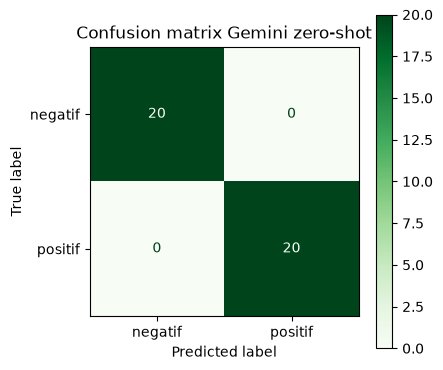

,fold,n,accuracy,macro_f1
0,0,8,1.0,1.0
1,1,8,1.0,1.0
2,2,8,1.0,1.0
3,3,8,1.0,1.0
4,4,8,1.0,1.0


Rata-rata ± std Accuracy : 1.000 ± 0.000
Rata-rata ± std Macro-F1 : 1.000 ± 0.000
Jumlah teks salah prediksi (Gemini): 0 dari 40
Tidak ada kesalahan prediksi Gemini pada data ini.
N_RUNS = 1, analisis konsistensi dilewati. Ubah N_RUNS ke 3 jika ingin mengukurnya.


,attempts,latency_sec,prompt_tokens,output_tokens,total_tokens,n_missing,n_extra,problem
0,1,228.052,768,394,2051,0,0,None


Latency per batch (40 teks): 228.05 detik
Estimasi latency per teks            : 5701.3 ms (total batch dibagi jumlah teks, BUKAN latency per-teks sebenarnya)
Token per batch: prompt=768, output=394, total=2051
Harga belum diisi (PRICE_INPUT_PER_M / PRICE_OUTPUT_PER_M), biaya tidak dihitung.


,metode,accuracy_gabungan,macro_f1_gabungan,macro_f1_mean_per_fold,macro_f1_std_per_fold
0,Scikit-learn (TF-IDF + LogReg),0.775,0.774,0.763,0.155
1,Gemini zero-shot,1.000,1.000,1.000,0.000


Tabel kesepakatan (jumlah teks):


gm_correct,gemini benar,All
sk_correct,,
sklearn benar,31,31
sklearn salah,9,9
All,40,40


Teks di mana hanya salah satu yang benar: 9


,text_id,review_text,sentiment,pred_sklearn,pred_gemini_name,sk_correct,gm_correct
0,0,Pelayanan lambat dan tidak responsif saat dikomplain.,negatif,1,negatif,False,True
7,7,"Bahan nyaman dipakai, ukuran pas, tidak mengecewakan.",positif,0,positif,False,True
10,10,Barang tidak berfungsi sama sekali begitu diterima.,negatif,1,negatif,False,True
18,18,"Bahan murahan, tidak sesuai dengan harga yang dibayarkan.",negatif,1,negatif,False,True
19,19,"Kualitas produk sangat memuaskan, akan order lagi.",positif,0,positif,False,True
20,20,"Sangat mengecewakan, uang saya seperti terbuang percuma.",negatif,1,negatif,False,True
21,21,"Ukuran dan warna berbeda dari pesanan, sangat kecewa.",negatif,1,negatif,False,True
24,24,"Produknya rapi dan bersih, tidak ada cacat sama sekali.",positif,0,positif,False,True
30,30,"Pengalaman belanja terburuk, tidak akan order lagi disini.",negatif,1,negatif,False,True


Tersimpan di memori: df_llm dan gemini_run_info
Model: gemini-3.5-flash | temperature: 0.0 | jumlah run: 1


In [13]:
# Prediksi utama = run pertama
df_llm["pred_gemini_name"] = df_llm["pred_gemini_run0"]
df_llm["pred_gemini"] = df_llm["pred_gemini_name"].map(LABEL_MAP)  # NaN jika tidak valid

n_invalid = int(df_llm["pred_gemini"].isna().sum())
print(f"\nOutput invalid/hilang (run utama): {n_invalid} dari {len(df_llm)} "
      f"({n_invalid / len(df_llm):.1%})")
df_llm[["text_id", "review_text", "sentiment", "pred_gemini_name", "fold"]].head(10)


# %% [8] Evaluasi Gemini (pada teks yang outputnya valid)
valid = df_llm["pred_gemini"].notna()
y_true = df_llm.loc[valid, "label"].astype(int)
y_pred = df_llm.loc[valid, "pred_gemini"].astype(int)
target_names = [LABEL_NAMES[0], LABEL_NAMES[1]]

print(f"Teks yang dievaluasi: {int(valid.sum())} dari {len(df_llm)}")
print(f"Accuracy : {accuracy_score(y_true, y_pred):.3f}")
print(f"Macro-F1 : {f1_score(y_true, y_pred, average='macro'):.3f}\n")
print(classification_report(y_true, y_pred, target_names=target_names, digits=3))

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, display_labels=target_names, cmap="Greens", ax=ax
)
ax.set_title("Confusion matrix Gemini zero-shot")
plt.tight_layout()
plt.show()


# %% [9] Metrik per fold (agar sebanding dengan Scikit-learn)
def fold_metrics(df_in: pd.DataFrame, pred_col: str) -> pd.DataFrame:
    rows = []
    for k in sorted(df_in["fold"].unique()):
        sub = df_in[(df_in["fold"] == k) & df_in[pred_col].notna()]
        yt, yp = sub["label"].astype(int), sub[pred_col].astype(int)
        rows.append({
            "fold": k,
            "n": len(sub),
            "accuracy": accuracy_score(yt, yp),
            "macro_f1": f1_score(yt, yp, average="macro"),
        })
    return pd.DataFrame(rows)


fm_gemini = fold_metrics(df_llm, "pred_gemini")
display(fm_gemini.round(4))
print(f"Rata-rata ± std Accuracy : {fm_gemini['accuracy'].mean():.3f} ± {fm_gemini['accuracy'].std():.3f}")
print(f"Rata-rata ± std Macro-F1 : {fm_gemini['macro_f1'].mean():.3f} ± {fm_gemini['macro_f1'].std():.3f}")


# %% [10] Error analysis Gemini
errors_g = df_llm[valid & (df_llm["pred_gemini"] != df_llm["label"])]
print(f"Jumlah teks salah prediksi (Gemini): {len(errors_g)} dari {int(valid.sum())}")
if len(errors_g) > 0:
    pd.set_option("display.max_colwidth", None)
    display(errors_g[["text_id", "review_text", "sentiment", "pred_gemini_name", "fold"]])
else:
    print("Tidak ada kesalahan prediksi Gemini pada data ini.")


# %% [11] Konsistensi antar-run (hanya bermakna jika N_RUNS > 1)
if N_RUNS > 1:
    run_cols = [f"pred_gemini_run{r}" for r in range(N_RUNS)]
    same = df_llm[run_cols].nunique(axis=1) == 1
    print(f"Teks dengan label identik di semua {N_RUNS} run: "
          f"{int(same.sum())} dari {len(df_llm)} ({same.mean():.1%})")
    if (~same).any():
        display(df_llm.loc[~same, ["text_id", "review_text", "sentiment"] + run_cols])
else:
    print("N_RUNS = 1, analisis konsistensi dilewati. Ubah N_RUNS ke 3 jika ingin mengukurnya.")


# %% [12] Biaya & latency (data untuk analisis trade-off)
runs_df = pd.DataFrame([i for _, i in runs])
display(runs_df.round(3))

mean_latency = runs_df["latency_sec"].mean()
print(f"Latency per batch ({len(df_llm)} teks): {mean_latency:.2f} detik")
print(f"Estimasi latency per teks            : {mean_latency / len(df_llm) * 1000:.1f} ms "
      f"(total batch dibagi jumlah teks, BUKAN latency per-teks sebenarnya)")
print(f"Token per batch: prompt={runs_df['prompt_tokens'].mean():.0f}, "
      f"output={runs_df['output_tokens'].mean():.0f}, total={runs_df['total_tokens'].mean():.0f}")

if PRICE_INPUT_PER_M is not None and PRICE_OUTPUT_PER_M is not None:
    cost = (runs_df["prompt_tokens"].mean() * PRICE_INPUT_PER_M
            + runs_df["output_tokens"].mean() * PRICE_OUTPUT_PER_M) / 1_000_000
    print(f"Estimasi biaya per batch   : ${cost:.6f}")
    print(f"Estimasi biaya per 1.000 teks: ${cost / len(df_llm) * 1000:.4f}")
else:
    print("Harga belum diisi (PRICE_INPUT_PER_M / PRICE_OUTPUT_PER_M), biaya tidak dihitung.")


# %% [13] Perbandingan Scikit-learn vs Gemini (pada teks yang sama)
cmp = df_llm[valid].copy()
cmp["sk_correct"] = cmp["pred_sklearn"].astype(int) == cmp["label"].astype(int)
cmp["gm_correct"] = cmp["pred_gemini"].astype(int) == cmp["label"].astype(int)

fm_sk = fold_metrics(cmp, "pred_sklearn")
fm_gm = fold_metrics(cmp, "pred_gemini")

summary = pd.DataFrame({
    "metode": ["Scikit-learn (TF-IDF + LogReg)", "Gemini zero-shot"],
    "accuracy_gabungan": [
        accuracy_score(cmp["label"], cmp["pred_sklearn"].astype(int)),
        accuracy_score(cmp["label"], cmp["pred_gemini"].astype(int)),
    ],
    "macro_f1_gabungan": [
        f1_score(cmp["label"], cmp["pred_sklearn"].astype(int), average="macro"),
        f1_score(cmp["label"], cmp["pred_gemini"].astype(int), average="macro"),
    ],
    "macro_f1_mean_per_fold": [fm_sk["macro_f1"].mean(), fm_gm["macro_f1"].mean()],
    "macro_f1_std_per_fold": [fm_sk["macro_f1"].std(), fm_gm["macro_f1"].std()],
}).round(3)
display(summary)

print("Tabel kesepakatan (jumlah teks):")
display(pd.crosstab(
    cmp["sk_correct"].map({True: "sklearn benar", False: "sklearn salah"}),
    cmp["gm_correct"].map({True: "gemini benar", False: "gemini salah"}),
    margins=True,
))

pd.set_option("display.max_colwidth", None)
diff = cmp[cmp["sk_correct"] != cmp["gm_correct"]]
print(f"Teks di mana hanya salah satu yang benar: {len(diff)}")
if len(diff) > 0:
    display(diff[["text_id", "review_text", "sentiment", "pred_sklearn", "pred_gemini_name",
                  "sk_correct", "gm_correct"]])


# %% [14] Simpan hasil di memori untuk tahap berikutnya (TIDAK ditulis ke file)
# df_llm sudah memuat semua prediksi. Info run dikemas dalam satu dict.
gemini_run_info = {
    "model": MODEL_NAME,
    "temperature": TEMPERATURE,
    "n_runs": N_RUNS,
    "runs": [i for _, i in runs],
}

print("Tersimpan di memori: df_llm dan gemini_run_info")
print(f"Model: {gemini_run_info['model']} | temperature: {gemini_run_info['temperature']} "
      f"| jumlah run: {gemini_run_info['n_runs']}")

## 6. Evaluasi dan Perbandingan

### 6.1 Evaluasi Model Klasik

Total teks unik            : 40
Output Gemini tidak valid  : 0
Teks yang dievaluasi       : 40
Distribusi label asli      : negatif=20, positif=20
Model Klasik (Scikit-learn: TF-IDF + Logistic Regression), prediksi out-of-fold 5-fold
Accuracy      : 0.775
Macro-F1      : 0.774
Benar / Salah : 31 / 9  (dari 40 teks)

Classification report:


,precision,recall,f1-score,support
negatif,0.824,0.700,0.757,20
positif,0.739,0.850,0.791,20
macro avg,0.781,0.775,0.774,40


Confusion matrix (angka):


,prediksi: negatif,prediksi: positif
asli: negatif,14,6
asli: positif,3,17


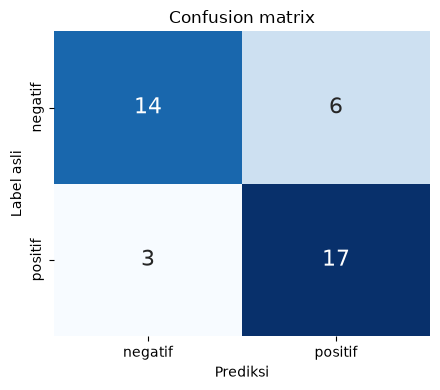

In [15]:
# 05_evaluasi_perbandingan_v2.py
# Bagian 6: Evaluasi dan Perbandingan
#   6.1 Evaluasi Model Klasik   (ditampilkan sendiri)
#   6.2 Evaluasi LLM API        (ditampilkan sendiri)
#   6.3 Perbandingan berdampingan
#   6.4 Perbandingan operasional (waktu, token, dll.)
#
# VERSI IN-MEMORY: tidak membaca atau menulis file hasil.
#
# Prasyarat: cell import (np, pd, plt, sns, accuracy_score, f1_score,
# confusion_matrix, classification_report) sudah dijalankan, dan variabel
# berikut ada di memori dari tahap sebelumnya:
#   df_llm, sk_fold_metrics, gemini_run_info
#
# Nama variabel mengikuti notebook starter: y_test, y_pred_classic, y_pred_llm.
# Setiap blok "# %%" = satu cell. Blok "# %% [markdown]" = cell teks (judul).
# ============================================================
 
# %% [markdown]
# # 6. Evaluasi dan Perbandingan
 
# %% [0] Siapkan data evaluasi
from sklearn.metrics import precision_recall_fscore_support
 
assert all(v in globals() for v in ["df_llm", "sk_fold_metrics", "gemini_run_info"]), (
    "Variabel df_llm / sk_fold_metrics / gemini_run_info belum ada. "
    "Jalankan 02_eda_pipeline_sklearn_v2.py dan 04_gemini_zeroshot_v2.py sampai selesai."
)
 
LABELS = [0, 1]
TARGET_NAMES = ["negatif", "positif"]
 
df_eval = df_llm.copy()
n_total = len(df_eval)
 
# Evaluasi hanya pada teks yang output Gemini-nya valid, dan dipakai untuk
# KEDUA metode agar perbandingannya dilakukan pada teks yang persis sama.
valid = df_eval["pred_gemini"].notna()
n_invalid = int((~valid).sum())
df_eval = df_eval[valid].copy()
 
y_test = df_eval["label"].astype(int).to_numpy()
y_pred_classic = df_eval["pred_sklearn"].astype(int).to_numpy()
y_pred_llm = df_eval["pred_gemini"].astype(int).to_numpy()
 
print(f"Total teks unik            : {n_total}")
print(f"Output Gemini tidak valid  : {n_invalid}")
print(f"Teks yang dievaluasi       : {len(y_test)}")
print(f"Distribusi label asli      : "
      f"negatif={int((y_test == 0).sum())}, positif={int((y_test == 1).sum())}")
 
 
# %% [0b] Fungsi bantu tampilan
def report_table(y_true, y_pred):
    """Classification report sebagai tabel rapi (precision, recall, F1, support)."""
    p, r, f, s = precision_recall_fscore_support(
        y_true, y_pred, labels=LABELS, zero_division=0
    )
    rows = {
        TARGET_NAMES[i]: {"precision": p[i], "recall": r[i], "f1-score": f[i], "support": s[i]}
        for i in range(len(LABELS))
    }
    mp, mr, mf, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=LABELS, average="macro", zero_division=0
    )
    rows["macro avg"] = {"precision": mp, "recall": mr, "f1-score": mf, "support": s.sum()}
    out = pd.DataFrame(rows).T
    out["support"] = out["support"].astype(int)
    return out.round(3)
 
 
def cm_table(y_true, y_pred):
    """Confusion matrix sebagai tabel berlabel."""
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)
    return pd.DataFrame(
        cm,
        index=[f"asli: {n}" for n in TARGET_NAMES],
        columns=[f"prediksi: {n}" for n in TARGET_NAMES],
    )
 
 
def plot_cm(ax, y_true, y_pred, title, cmap):
    """Confusion matrix sebagai heatmap berisi jumlah."""
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap=cmap, cbar=False,
        xticklabels=TARGET_NAMES, yticklabels=TARGET_NAMES,
        annot_kws={"size": 16}, ax=ax,
    )
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Label asli")
    ax.set_title(title)
 
 
def show_evaluation(title, y_true, y_pred, cmap):
    n_wrong = int((y_true != y_pred).sum())
    print("=" * 60)
    print(title)
    print("=" * 60)
    print(f"Accuracy      : {accuracy_score(y_true, y_pred):.3f}")
    print(f"Macro-F1      : {f1_score(y_true, y_pred, average='macro'):.3f}")
    print(f"Benar / Salah : {len(y_true) - n_wrong} / {n_wrong}  (dari {len(y_true)} teks)\n")
 
    print("Classification report:")
    display(report_table(y_true, y_pred))
 
    print("Confusion matrix (angka):")
    display(cm_table(y_true, y_pred))
 
    fig, ax = plt.subplots(figsize=(4.5, 4))
    plot_cm(ax, y_true, y_pred, "Confusion matrix", cmap)
    plt.tight_layout()
    plt.show()
 
 
# %% [markdown]
# ## 6.1 Evaluasi Model Klasik
 
# %% [6.1] Evaluasi Model Klasik (Scikit-learn)
show_evaluation(
    "Model Klasik (Scikit-learn: TF-IDF + Logistic Regression), prediksi out-of-fold 5-fold",
    y_test, y_pred_classic, cmap="Blues",
)

### 6.2 Evaluasi LLM API

LLM API (Gemini zero-shot, 1 call batch)
Accuracy      : 1.000
Macro-F1      : 1.000
Benar / Salah : 40 / 0  (dari 40 teks)

Classification report:


,precision,recall,f1-score,support
negatif,1.0,1.0,1.0,20
positif,1.0,1.0,1.0,20
macro avg,1.0,1.0,1.0,40


Confusion matrix (angka):


,prediksi: negatif,prediksi: positif
asli: negatif,20,0
asli: positif,0,20


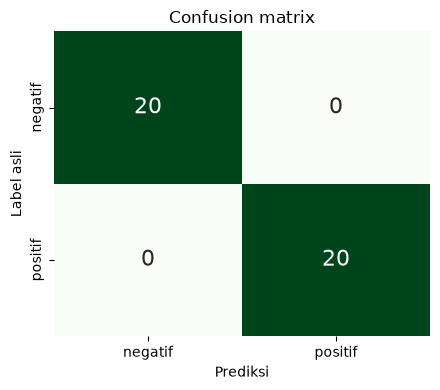

In [16]:
 # [6.2] Evaluasi LLM API (Gemini zero-shot)
show_evaluation(
    "LLM API (Gemini zero-shot, 1 call batch)",
    y_test, y_pred_llm, cmap="Greens",
)

### 6.3 Tabel Perbandingan Ringkasan

_Susun tabel ringkasan (bisa markdown table atau DataFrame) yang membandingkan Accuracy, Precision, Recall, F1-Score kedua pendekatan._

In [18]:
# ============================================================
# 06_tabel_ringkasan_v2.py
# 6.3 Tabel Perbandingan Ringkasan
# Membandingkan Accuracy, Precision, Recall, F1-Score kedua pendekatan.
#
# VERSI IN-MEMORY: tidak membaca atau menulis file. Teks Markdown dicetak
# di cell, tinggal disalin ke cell markdown / laporan.
#
# Prasyarat: np, pd, accuracy_score sudah di-import di cell import, dan
# variabel df_llm ada di memori (dari 04_gemini_zeroshot_v2.py).
#
# Setiap blok "# %%" = satu cell notebook.
# ============================================================

# %% [markdown]
# ## 6.3 Tabel Perbandingan Ringkasan

# %% [1] Siapkan data (teks yang sama untuk kedua pendekatan)
from sklearn.metrics import precision_recall_fscore_support
from IPython.display import Markdown, display

assert "df_llm" in globals(), (
    "df_llm belum ada. Jalankan 04_gemini_zeroshot_v2.py sampai selesai terlebih dulu."
)

LABELS = [0, 1]
TARGET_NAMES = ["negatif", "positif"]
AVERAGE = "macro"   # ganti ke "weighted" jika ingin rata-rata berbobot jumlah data

n_total = len(df_llm)

# Hanya teks yang output Gemini-nya valid, berlaku untuk KEDUA metode
df_sum = df_llm[df_llm["pred_gemini"].notna()].copy()

y_test = df_sum["label"].astype(int).to_numpy()
y_pred_classic = df_sum["pred_sklearn"].astype(int).to_numpy()
y_pred_llm = df_sum["pred_gemini"].astype(int).to_numpy()

print(f"Teks yang dibandingkan: {len(y_test)} dari {n_total}")


# %% [2] Tabel ringkasan: Accuracy, Precision, Recall, F1-Score
def overall_metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=LABELS, average=AVERAGE, zero_division=0
    )
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        f"Precision ({AVERAGE})": p,
        f"Recall ({AVERAGE})": r,
        f"F1-Score ({AVERAGE})": f,
    }


SEL_COL = "Selisih (Gemini - Scikit-learn)"

summary = pd.DataFrame({
    "Scikit-learn": overall_metrics(y_test, y_pred_classic),
    "Gemini zero-shot": overall_metrics(y_test, y_pred_llm),
}).round(3)
summary[SEL_COL] = (summary["Gemini zero-shot"] - summary["Scikit-learn"]).round(3)
summary["Lebih tinggi"] = np.select(
    [summary[SEL_COL] > 0, summary[SEL_COL] < 0],
    ["Gemini zero-shot", "Scikit-learn"],
    default="Sama",
)
summary.index.name = "Metrik"

display(summary)
print(f"Catatan: dengan {len(y_test)} teks, satu prediksi berbeda setara ±{1 / len(y_test):.1%} accuracy.")


# %% [3] Tabel rincian per kelas (Precision, Recall, F1-Score)
p_sk, r_sk, f_sk, support = precision_recall_fscore_support(
    y_test, y_pred_classic, labels=LABELS, zero_division=0
)
p_gm, r_gm, f_gm, _ = precision_recall_fscore_support(
    y_test, y_pred_llm, labels=LABELS, zero_division=0
)

rows = []
for i, name in enumerate(TARGET_NAMES):
    for metrik, a, b in [
        ("Precision", p_sk[i], p_gm[i]),
        ("Recall", r_sk[i], r_gm[i]),
        ("F1-Score", f_sk[i], f_gm[i]),
    ]:
        rows.append({
            "Kelas - Metrik": f"{name} - {metrik}",
            "Scikit-learn": a,
            "Gemini zero-shot": b,
        })

per_class = pd.DataFrame(rows).set_index("Kelas - Metrik").round(3)
per_class[SEL_COL] = (per_class["Gemini zero-shot"] - per_class["Scikit-learn"]).round(3)

display(per_class)
print("Jumlah data per kelas (support):",
      {TARGET_NAMES[i]: int(support[i]) for i in range(len(LABELS))})


# %% [4] Versi Markdown table (siap ditempel ke cell markdown / laporan)
def df_to_markdown(df: pd.DataFrame, floatfmt: str = ".3f") -> str:
    cols = [df.index.name or ""] + list(df.columns)
    lines = [
        "| " + " | ".join(cols) + " |",
        "|" + "|".join(["---"] * len(cols)) + "|",
    ]
    for idx, row in df.iterrows():
        vals = [f"{v:{floatfmt}}" if isinstance(v, (float, np.floating)) else str(v) for v in row]
        lines.append("| " + " | ".join([str(idx)] + vals) + " |")
    return "\n".join(lines)


summary_md = summary.copy()
summary_md[SEL_COL] = summary_md[SEL_COL].map(lambda v: f"{v:+.3f}")
per_class_md = per_class.copy()
per_class_md[SEL_COL] = per_class_md[SEL_COL].map(lambda v: f"{v:+.3f}")

md_summary = df_to_markdown(summary_md)
md_per_class = df_to_markdown(per_class_md)

print("----- Markdown: tabel ringkasan (salin teks di bawah) -----")
print(md_summary)
print("\n----- Markdown: tabel per kelas (salin teks di bawah) -----")
print(md_per_class)

print("\n----- Tampilan terender -----")
display(Markdown("**Tabel ringkasan**\n\n" + md_summary))
display(Markdown("**Tabel per kelas**\n\n" + md_per_class))

Teks yang dibandingkan: 40 dari 40


,Scikit-learn,Gemini zero-shot,Selisih (Gemini - Scikit-learn),Lebih tinggi
Metrik,,,,
Accuracy,0.775,1.0,0.225,Gemini zero-shot
Precision (macro),0.781,1.0,0.219,Gemini zero-shot
Recall (macro),0.775,1.0,0.225,Gemini zero-shot
F1-Score (macro),0.774,1.0,0.226,Gemini zero-shot


Catatan: dengan 40 teks, satu prediksi berbeda setara ±2.5% accuracy.


,Scikit-learn,Gemini zero-shot,Selisih (Gemini - Scikit-learn)
Kelas - Metrik,,,
negatif - Precision,0.824,1.0,0.176
negatif - Recall,0.700,1.0,0.300
negatif - F1-Score,0.757,1.0,0.243
positif - Precision,0.739,1.0,0.261
positif - Recall,0.850,1.0,0.150
positif - F1-Score,0.791,1.0,0.209


Jumlah data per kelas (support): {'negatif': 20, 'positif': 20}
----- Markdown: tabel ringkasan (salin teks di bawah) -----
| Metrik | Scikit-learn | Gemini zero-shot | Selisih (Gemini - Scikit-learn) | Lebih tinggi |
|---|---|---|---|---|
| Accuracy | 0.775 | 1.000 | +0.225 | Gemini zero-shot |
| Precision (macro) | 0.781 | 1.000 | +0.219 | Gemini zero-shot |
| Recall (macro) | 0.775 | 1.000 | +0.225 | Gemini zero-shot |
| F1-Score (macro) | 0.774 | 1.000 | +0.226 | Gemini zero-shot |

----- Markdown: tabel per kelas (salin teks di bawah) -----
| Kelas - Metrik | Scikit-learn | Gemini zero-shot | Selisih (Gemini - Scikit-learn) |
|---|---|---|---|
| negatif - Precision | 0.824 | 1.000 | +0.176 |
| negatif - Recall | 0.700 | 1.000 | +0.300 |
| negatif - F1-Score | 0.757 | 1.000 | +0.243 |
| positif - Precision | 0.739 | 1.000 | +0.261 |
| positif - Recall | 0.850 | 1.000 | +0.150 |
| positif - F1-Score | 0.791 | 1.000 | +0.209 |

----- Tampilan terender -----


**Tabel ringkasan**

| Metrik | Scikit-learn | Gemini zero-shot | Selisih (Gemini - Scikit-learn) | Lebih tinggi |
|---|---|---|---|---|
| Accuracy | 0.775 | 1.000 | +0.225 | Gemini zero-shot |
| Precision (macro) | 0.781 | 1.000 | +0.219 | Gemini zero-shot |
| Recall (macro) | 0.775 | 1.000 | +0.225 | Gemini zero-shot |
| F1-Score (macro) | 0.774 | 1.000 | +0.226 | Gemini zero-shot |

**Tabel per kelas**

| Kelas - Metrik | Scikit-learn | Gemini zero-shot | Selisih (Gemini - Scikit-learn) |
|---|---|---|---|
| negatif - Precision | 0.824 | 1.000 | +0.176 |
| negatif - Recall | 0.700 | 1.000 | +0.300 |
| negatif - F1-Score | 0.757 | 1.000 | +0.243 |
| positif - Precision | 0.739 | 1.000 | +0.261 |
| positif - Recall | 0.850 | 1.000 | +0.150 |
| positif - F1-Score | 0.791 | 1.000 | +0.209 |

## 7. Analisis Trade-off dan Limitation

### 7.1 Perbandingan Performa
Berdasarkan eksperimen pada 40 teks ulasan unik dengan distribusi seimbang (20 positif dan 20 negatif), Gemini zero-shot memperoleh hasil evaluasi lebih tinggi dibandingkan model klasik Scikit-learn. Gemini mencatat Accuracy sebesar 1,000 dan Macro-F1 sebesar 1,000, sedangkan Scikit-learn (TF-IDF + Logistic Regression) memperoleh Accuracy 0,775 dan Macro-F1 0,774.

Pada model Scikit-learn, confusion matrix menunjukkan 14 ulasan negatif dan 17 ulasan positif berhasil diklasifikasikan dengan benar. Terdapat 6 ulasan negatif yang diprediksi positif dan 3 ulasan positif yang diprediksi negatif. Dengan demikian, model klasik menghasilkan 9 kesalahan dari 40 ulasan. Sementara itu, Gemini mengklasifikasikan seluruh 40 ulasan dengan benar pada satu kali pengujian, tanpa output yang hilang atau tidak valid.

Hasil ini menunjukkan Gemini lebih unggul pada dataset eksperimen yang digunakan. Namun, skor sempurna tersebut tidak boleh langsung dianggap sebagai bukti bahwa Gemini akan selalu memiliki performa sempurna pada data baru. Jumlah teks unik hanya 40, sehingga cakupan variasi bahasa, gaya penulisan, dan konteks ulasan masih terbatas.
### 7.2 Trade-off Implementasi, Kecepatan, dan Biaya
Scikit-learn (TF-IDF + Logistic Regression) membutuhkan tahap preprocessing, ekstraksi fitur, pelatihan, dan evaluasi. Pipeline menggunakan TF-IDF unigram-bigram dan Logistic Regression dengan class_weight="balanced". Waktu training rata-rata per fold berada pada kisaran beberapa milidetik, sedangkan waktu prediksi tercatat sekitar 0,31–0,52 ms per teks. Setelah model selesai dilatih, inference dapat dijalankan secara lokal tanpa biaya API per permintaan. Pendekatan ini lebih mudah dikendalikan dari sisi lingkungan eksekusi dan privasi data, tetapi kualitasnya sangat bergantung pada representasi fitur serta data training yang tersedia.

Gemini zero-shot tidak memerlukan proses training atau penyusunan dataset pelatihan khusus. Implementasinya relatif langsung melalui prompt dan pemanggilan API. Pada eksperimen ini, satu batch berisi 40 teks selesai dalam sekitar 228,05 detik, menggunakan 768 prompt tokens, 394 output tokens, dan 2.051 total tokens menurut metadata respons. Angka latency tersebut merupakan waktu keseluruhan satu batch, bukan waktu inference individual yang terukur secara terpisah. Penggunaan API juga memerlukan koneksi internet, pengelolaan API key, dan berpotensi menimbulkan biaya berdasarkan penggunaan token. Biaya aktual belum dapat dihitung karena parameter harga input dan output pada notebook masih None.
### 7.3 Keterbatasan dan Potensi Kesalahan
- Scikit-learn: Model hanya belajar dari 40 teks unik. TF-IDF merepresentasikan kata dan kombinasi kata, sehingga konteks, ironi, sarkasme, serta hubungan antarfrasa yang lebih kompleks dapat kurang tertangkap. Kesalahan terlihat pada ulasan yang mengandung negasi atau frasa dengan polaritas yang bergantung pada konteks, misalnya “tidak mengecewakan” dan “tidak ada cacat sama sekali”. Nilai Macro-F1 antar-fold juga bervariasi (rata-rata 0,763 dengan standar deviasi 0,155), yang mengindikasikan performa belum stabil pada setiap pembagian data.
- Gemini: Walaupun memperoleh skor 1,000 pada pengujian ini, evaluasi hanya dilakukan dalam satu run (N_RUNS = 1), sehingga konsistensi hasil antar-run belum diukur. Pengujian juga menggunakan dataset kecil dan relatif terbatas variasi teksnya. Hasil satu batch tidak cukup untuk menyimpulkan performa pada ulasan baru yang lebih beragam. Selain itu, inference bergantung pada layanan eksternal, jaringan, ketersediaan model, batas penggunaan API, dan biaya token.
- Desain evaluasi: Data awal berjumlah 200 baris, tetapi setelah teks duplikat digabungkan hanya tersisa 40 teks unik. Scikit-learn dievaluasi menggunakan prediksi out-of-fold stratified 5-fold. Gemini memprediksi seluruh 40 teks unik dalam satu batch, lalu hasilnya dikelompokkan menurut fold untuk pelaporan. Dengan demikian, fold Gemini bukan evaluasi cross-validation dalam arti pelatihan ulang model per fold. Kedua pendekatan memang dibandingkan pada teks yang sama, tetapi hasil ini lebih tepat dipandang sebagai eksperimen awal pada kumpulan teks yang tersedia, bukan estimasi final performa produksi.
- Keterbatasan data: Duplikasi yang tinggi menunjukkan banyak baris merupakan pengulangan teks ulasan. Deduplication mencegah teks identik mendominasi evaluasi, tetapi jumlah contoh independen yang tersisa menjadi kecil. Generalisasi ke ulasan baru masih perlu diuji menggunakan data tambahan yang representatif.
Secara keseluruhan, Gemini unggul dari sisi metrik pada eksperimen ini, sedangkan Scikit-learn unggul dalam kecepatan inference lokal dan potensi efisiensi biaya untuk penggunaan berulang dalam skala besar. Keputusan produksi sebaiknya mempertimbangkan kebutuhan akurasi, latency, privasi, volume permintaan, dan anggaran API, bukan hanya skor pada dataset kecil ini.

## 8. Rekomendasi Technical Approach

Berdasarkan hasil eksperimen yang tersedia, Gemini zero-shot direkomendasikan sebagai kandidat utama untuk tahap validasi lanjutan, bukan langsung ditetapkan sebagai solusi produksi final. Pertimbangannya adalah Gemini memperoleh Accuracy 1,000 dan Macro-F1 1,000 pada 40 teks unik, lebih tinggi daripada Scikit-learn yang memperoleh Accuracy 0,775 dan Macro-F1 0,774. Gemini juga berhasil mengembalikan label valid untuk seluruh teks pada satu kali pemanggilan batch.

Rekomendasi ini tetap memiliki batasan penting. Dataset hanya menyisakan 40 teks unik setelah deduplikasi, Gemini baru diuji dalam satu run, dan latency satu batch mencapai sekitar 228,05 detik. Biaya API juga belum dihitung karena harga token belum dimasukkan ke konfigurasi notebook. Oleh karena itu, skor sempurna pada eksperimen ini belum cukup untuk menyatakan Gemini siap digunakan pada lingkungan produksi.

Sebelum keputusan produksi dibuat, tim disarankan melakukan langkah lanjutan berikut:
1. Menguji kedua pendekatan pada kumpulan ulasan baru yang lebih besar dan memiliki variasi bahasa, panjang teks, serta konteks sentimen yang lebih luas.
2. Menjalankan Gemini beberapa kali pada data evaluasi yang sama untuk memeriksa konsistensi prediksi, sekaligus mencatat latency dan penggunaan token setiap run.
3. Mengisi harga input dan output token sesuai tarif model yang benar-benar digunakan agar estimasi biaya dapat dihitung dan dibandingkan dengan biaya operasional model lokal.
4. Menetapkan target minimum untuk Accuracy, Macro-F1, latency, dan biaya sebelum memilih arsitektur produksi.
5. Mempertimbangkan Scikit-learn sebagai alternatif produksi apabila pengujian lanjutan menunjukkan performanya sudah memenuhi target, karena inference lokal jauh lebih cepat dan tidak menimbulkan biaya API per request.
Dengan demikian, keputusan teknis sementara adalah melanjutkan validasi Gemini sebagai kandidat dengan performa awal terbaik, sambil mempertahankan model Scikit-learn sebagai baseline lokal yang ringan. Pemilihan final harus menunggu pengujian pada data yang lebih representatif dan analisis biaya yang lengkap.